<a href="https://colab.research.google.com/github/sarahliu-mma/Quantitative-Trading-Pipeline_FIAM-Hackathon-2026/blob/main/notebooks/03_ridge_model_backtesting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [52]:
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

In [53]:
mt = pd.read_parquet('/content/drive/MyDrive/FIAM Hackathon/model_table.parquet')

In [54]:
IDENTIFIER = ['permno','eom']
TARGET = 'ret_exc_lead1m'
FEATURES = [f for f in mt.columns.tolist() if f not in IDENTIFIER+[TARGET]]
mt = mt.drop(columns=mt[FEATURES].select_dtypes('object').columns.tolist())
FEATURES = [f for f in mt.columns.tolist() if f not in IDENTIFIER+[TARGET]]
mt = mt.sort_values(['eom','permno']).reset_index(drop= True)

In [55]:
final_alpha = 10000

def ridge_backtesting(dt, alpha, pred_year, rolling_window):
    year = dt['eom'].dt.year
    train_roll_start = pred_year - rolling_window
    train = dt[(year >= train_roll_start) & (year < pred_year) ].dropna(subset=[TARGET])
    test = dt[year == pred_year]
    model = Ridge(alpha = alpha).fit(train[FEATURES].fillna(0.5),train[TARGET])
    test_pred = model.predict(test[FEATURES].fillna(0.5))
    result = test[IDENTIFIER+[TARGET]].copy()
    result['pred'] = test_pred
    monthly_ic = result.groupby('eom').apply(lambda g: g['pred'].corr(g[TARGET], method = 'spearman'))
    score = monthly_ic.mean()
    return(result,monthly_ic,score)

In [56]:
all_results = []
rows = []
for y in range(2021,2027):
  result, monthly_ic, score = ridge_backtesting(mt, final_alpha, y, 3)
  valid = result.dropna(subset=[TARGET])
  all_results.append(valid)
  rows.append({'year': y,
              'RMSE': np.sqrt(mean_squared_error(valid[TARGET], valid['pred'])),
              'R2_oos': 1 - ((valid[TARGET] - valid['pred'])**2).sum() / (valid[TARGET]**2).sum(),
              'mean_IC': score})

oos = pd.concat(all_results)
summary = pd.DataFrame(rows).set_index('year')
summary.loc['2021-2026'] = [
    np.sqrt(mean_squared_error(oos[TARGET], oos['pred'])),
    1 - ((oos[TARGET] - oos['pred'])**2).sum() / (oos[TARGET]**2).sum(),
    oos.groupby('eom').apply(lambda g: g['pred'].corr(g[TARGET], method='spearman')).mean()]
print(summary.round(4))

/tmp/ipykernel_3203/3276982096.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  monthly_ic = result.groupby('eom').apply(lambda g: g['pred'].corr(g[TARGET], method = 'spearman'))
/tmp/ipykernel_3203/3276982096.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  monthly_ic = result.groupby('eom').apply(lambda g: g['pred'].corr(g[TARGET], method = 'spearman'))
/tmp/ipykernel_3203/3276982096.py:12: Deprec

             RMSE  R2_oos  mean_IC
year                              
2021       0.1391 -0.0195  -0.1681
2022       0.1530 -0.0077   0.0522
2023       0.1447 -0.0061   0.0284
2024       0.1493 -0.0018   0.0543
2025       0.1512 -0.0006   0.0321
2026       0.1699  0.0069   0.0419
2021-2026  0.1498 -0.0052   0.0042


/tmp/ipykernel_3203/1912997893.py:17: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  oos.groupby('eom').apply(lambda g: g['pred'].corr(g[TARGET], method='spearman')).mean()]


In [57]:
print(oos.min(),oos.max())

permno                          10026
eom               2021-01-31 00:00:00
ret_exc_lead1m              -0.979766
pred                        -0.044266
dtype: object permno                          93436
eom               2026-07-31 00:00:00
ret_exc_lead1m               4.647645
pred                         0.040795
dtype: object


In [58]:
oos.head()

,permno,eom,ret_exc_lead1m,pred
195011,10026,2021-01-31,0.039913,0.015691
195012,10028,2021-01-31,-0.161387,0.008965
195013,10032,2021-01-31,0.091739,0.000027
195014,10051,2021-01-31,0.072673,0.009545
195015,10104,2021-01-31,0.067471,0.001625


In [59]:
oos['decile'] = oos.groupby('eom')['pred'].transform(lambda x: pd.qcut(x, 10, labels=False) + 1)
monthly_ret_mean = oos.groupby(['eom', 'decile'])[TARGET].mean().unstack()

In [67]:
oos['rank'] = oos.groupby('eom')['pred'].rank(ascending=False)
oos['n'] = oos.groupby('eom')['pred'].transform('count')
oos['side'] = np.where(oos['rank'] <= 150, 1, np.where(oos['rank'] > oos['n'] - 150, -1, 0))

In [61]:
import statsmodels.api as sm
import yfinance as yf

# 3-month T-bill (annual %) -> monthly decimal, dated at month-end
tb = pd.read_csv('https://fred.stlouisfed.org/graph/fredgraph.csv?id=TB3MS')
tb.columns = ['date', 'TB3MS']
tb['date'] = pd.to_datetime(tb['date']) + pd.offsets.MonthEnd(0)
rf = tb.set_index('date')['TB3MS'] / 100 / 12

# S&P 500 total return index -> monthly returns
sp = yf.download('^SP500TR', start='2020-12-01', end='2026-09-30',
                 auto_adjust=True, progress=False)['Close'].squeeze()
mkt = sp.resample('ME').last().pct_change()

# Decile long-short, labelled by the month the return is earned
ls_ret = monthly_ret_mean[10] - monthly_ret_mean[1]
ls_ret.index = ls_ret.index + pd.offsets.MonthEnd(1)

df = pd.DataFrame({'ls': ls_ret}).join(rf.rename('rf')).join(mkt.rename('mkt')).dropna()
df['total'] = df['ls'] + df['rf']          # spread + interest on cash collateral
df['bench'] = df['rf'] + 0.04 / 12         # cash + 4% per year
print(df.head(), df.shape)

                  ls        rf       mkt     total     bench
eom                                                         
2021-02-28  0.010704  0.000033  0.027575  0.010737  0.003367
2021-03-31 -0.130543  0.000025  0.043796 -0.130518  0.003358
2021-04-30 -0.013149  0.000017  0.053369 -0.013132  0.003350
2021-05-31 -0.047632  0.000017  0.006984 -0.047616  0.003350
2021-06-30  0.099646  0.000033  0.023345  0.099680  0.003367 (67, 5)


In [62]:
def ann_stats(r, rf, bench):
    excess = r - rf
    active = r - bench
    cum = (1 + r).cumprod()
    return pd.Series({
        'Annual return':         r.mean() * 12,
        'Annual vol':            r.std() * np.sqrt(12),
        'Sharpe (vs T-bill)':    excess.mean() / excess.std() * np.sqrt(12),
        'Active return (ann.)':  active.mean() * 12,
        'Tracking error (ann.)': active.std() * np.sqrt(12),
        'IR (vs cash+4%)':       active.mean() / active.std() * np.sqrt(12),
        'Max drawdown':          (cum / cum.cummax() - 1).min(),
        'Cumulative return':     cum.iloc[-1] - 1,
        '% months positive':     (r > 0).mean(),
    })

In [63]:
def alpha_beta(r, rf, mkt):
    y = r - rf
    X = sm.add_constant(mkt - rf)
    res = sm.OLS(y, X).fit()
    return pd.Series({'Alpha (ann.)': res.params.iloc[0] * 12,
                      'Alpha t-stat': res.tvalues.iloc[0],
                      'Beta':         res.params.iloc[1],
                      'Beta t-stat':  res.tvalues.iloc[1],
                      'R2':           res.rsquared})

In [66]:
# 1. Raw beta for each stock (from universe_panel, which keeps the unranked values)
ub = pd.read_parquet('/content/drive/MyDrive/FIAM Hackathon/universe_panel.parquet',
                     columns=['permno', 'eom', 'beta_60m'])

legs = oos[oos['side'] != 0].merge(ub, on=['permno', 'eom'], how='left')

# 2. Robust betas: shrink toward 1, missing -> 1
legs['beta_adj'] = 0.67 * legs['beta_60m'].fillna(1) + 0.33 * 1
leg_beta = legs.groupby(['eom', 'side'])['beta_adj'].mean().unstack()
leg_ret  = legs.groupby(['eom', 'side'])[TARGET].mean().unstack()
ret_long, ret_short = leg_ret[1], leg_ret[-1]

# 3. Hedge ratio limited so |net exposure| <= 50%, gross = 200%
h = (leg_beta[1] / leg_beta[-1]).clip(0.6, 1.667)
long_w  = 2 / (1 + h)
short_w = 2 * h / (1 + h)

print('Net exposure range:', (long_w - short_w).min(), (long_w - short_w).max())
print('Share of beta_60m missing by side:', legs.groupby('side')['beta_60m'].apply(lambda x: x.isna().mean()).round(3).to_dict())

# 4. Portfolio return, labelled by the month it is earned
bn = long_w * ret_long - short_w * ret_short
bn.index = bn.index + pd.offsets.MonthEnd(1)

df['bn_total'] = bn.reindex(df.index) + df['rf']

print(pd.DataFrame({'Decile, dollar-neutral': ann_stats(df['total'],    df['rf'], df['bench']),
                    '150/150, beta-neutral':  ann_stats(df['bn_total'], df['rf'], df['bench'])}).round(3))
print(pd.DataFrame({'Decile, dollar-neutral': alpha_beta(df['total'],    df['rf'], df['mkt']),
                    '150/150, beta-neutral':  alpha_beta(df['bn_total'], df['rf'], df['mkt'])}).round(3))

Net exposure range: -0.5001874765654295 0.10888417390356053
Share of beta_60m missing by side: {-1: 0.273, 1: 0.103}
                       Decile, dollar-neutral  150/150, beta-neutral
Annual return                           0.047                  0.033
Annual vol                              0.201                  0.231
Sharpe (vs T-bill)                      0.071                 -0.001
Active return (ann.)                   -0.026                 -0.040
Tracking error (ann.)                   0.199                  0.230
IR (vs cash+4%)                        -0.130                 -0.175
Max drawdown                           -0.489                 -0.505
Cumulative return                       0.163                  0.038
% months positive                       0.627                  0.582
              Decile, dollar-neutral  150/150, beta-neutral
Alpha (ann.)                   0.002                  0.029
Alpha t-stat                   0.028                  0.295
Beta         

In [68]:
# 150/150 dollar-neutral: $1 long top 150, $1 short bottom 150
dn = ret_long - ret_short
dn.index = dn.index + pd.offsets.MonthEnd(1)        # label by the month the return is earned
df['dn_total'] = dn.reindex(df.index) + df['rf']    # spread + interest on cash collateral

print(pd.DataFrame({'Decile, dollar-neutral':  ann_stats(df['total'],    df['rf'], df['bench']),
                    '150/150, dollar-neutral': ann_stats(df['dn_total'], df['rf'], df['bench']),
                    '150/150, beta-neutral':   ann_stats(df['bn_total'], df['rf'], df['bench'])}).round(3))

print(pd.DataFrame({'Decile, dollar-neutral':  alpha_beta(df['total'],    df['rf'], df['mkt']),
                    '150/150, dollar-neutral': alpha_beta(df['dn_total'], df['rf'], df['mkt']),
                    '150/150, beta-neutral':   alpha_beta(df['bn_total'], df['rf'], df['mkt'])}).round(3))

                       Decile, dollar-neutral  150/150, dollar-neutral  \
Annual return                           0.047                    0.042   
Annual vol                              0.201                    0.228   
Sharpe (vs T-bill)                      0.071                    0.037   
Active return (ann.)                   -0.026                   -0.032   
Tracking error (ann.)                   0.199                    0.227   
IR (vs cash+4%)                        -0.130                   -0.140   
Max drawdown                           -0.489                   -0.531   
Cumulative return                       0.163                    0.089   
% months positive                       0.627                    0.642   

                       150/150, beta-neutral  
Annual return                          0.033  
Annual vol                             0.231  
Sharpe (vs T-bill)                    -0.001  
Active return (ann.)                  -0.040  
Tracking error (ann.)   

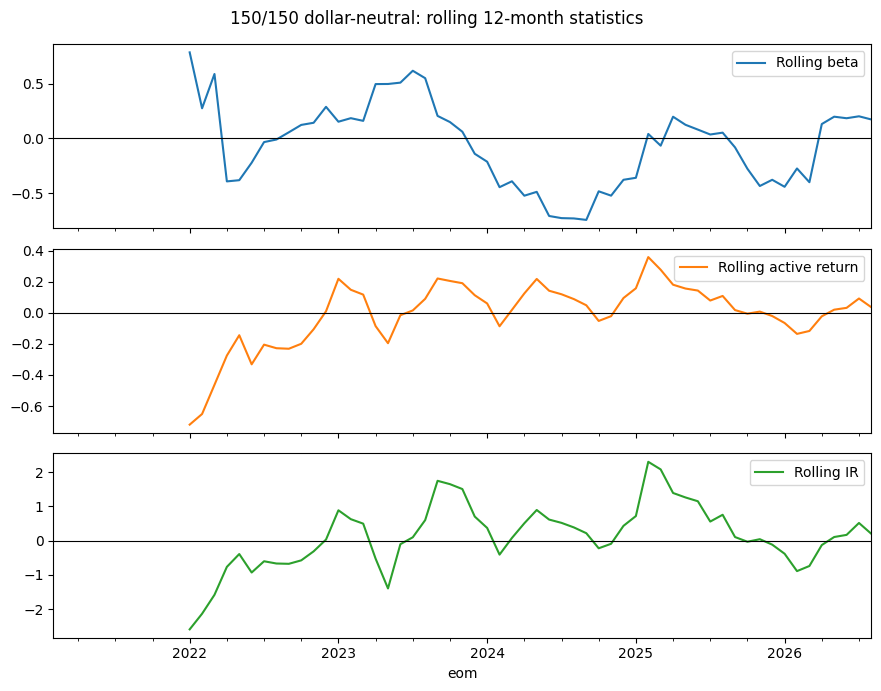

count    56.000
mean     -0.053
std       0.377
min      -0.743
25%      -0.384
50%       0.038
75%       0.184
max       0.784
Name: Rolling beta, dtype: float64


In [69]:
w = 12
ex  = df['dn_total'] - df['rf']        # portfolio excess return
mx  = df['mkt'] - df['rf']             # market excess return
act = df['dn_total'] - df['bench']     # return above cash + 4%

roll = pd.DataFrame({
    'Rolling beta':          ex.rolling(w).cov(mx) / mx.rolling(w).var(),
    'Rolling active return': act.rolling(w).mean() * 12,
    'Rolling IR':            act.rolling(w).mean() / act.rolling(w).std() * np.sqrt(12),
})

axes = roll.plot(subplots=True, figsize=(9, 7), title='150/150 dollar-neutral: rolling 12-month statistics')
for ax in axes:
    ax.axhline(0, color='black', linewidth=0.8)
plt.tight_layout(); plt.show()

print(roll['Rolling beta'].describe().round(3))

In [70]:
# Raw bid-ask spread estimate (model_table only has it as a rank)
spread = pd.read_parquet('/content/drive/MyDrive/FIAM Hackathon/universe_panel.parquet',
                         columns=['permno', 'eom', 'bidaskhl_21d'])

legs_c = oos[oos['side'] != 0].merge(spread, on=['permno', 'eom'], how='left')

# Weight of each stock: +1/150 long, -1/150 short (uses each month's actual count, in case of ties)
legs_c['w'] = legs_c['side'] / legs_c.groupby(['eom', 'side'])['permno'].transform('count')

W  = legs_c.pivot_table(index='eom', columns='permno', values='w', fill_value=0)   # month x stock
dW = W.diff().abs()
dW.iloc[0] = W.iloc[0].abs()               # first month: buy everything from scratch
turnover = dW.sum(axis=1)                  # total weight traded each month

S = legs_c.pivot_table(index='eom', columns='permno', values='bidaskhl_21d').reindex_like(W)
S = S.fillna(S.stack().median())           # missing spread -> typical spread
cost = (dW * S / 2).sum(axis=1)            # pay half the spread on each trade
cost.index = cost.index + pd.offsets.MonthEnd(1)    # align with the month the return is earned

df['dn_net'] = df['dn_total'] - cost.reindex(df.index).fillna(0)

print('Average monthly turnover (excl. first month):', turnover.iloc[1:].mean().round(2))
print('Average monthly cost:', cost.mean().round(4))
print(pd.DataFrame({'Gross': ann_stats(df['dn_total'], df['rf'], df['bench']),
                    'Net':   ann_stats(df['dn_net'],   df['rf'], df['bench'])}).round(3))
print(pd.DataFrame({'Gross': alpha_beta(df['dn_total'], df['rf'], df['mkt']),
                    'Net':   alpha_beta(df['dn_net'],   df['rf'], df['mkt'])}).round(3))

Average monthly turnover (excl. first month): 1.66
Average monthly cost: 0.0095
                       Gross    Net
Annual return          0.042 -0.073
Annual vol             0.228  0.227
Sharpe (vs T-bill)     0.037 -0.471
Active return (ann.)  -0.032 -0.146
Tracking error (ann.)  0.227  0.226
IR (vs cash+4%)       -0.140 -0.648
Max drawdown          -0.531 -0.588
Cumulative return      0.089 -0.427
% months positive      0.642  0.552
              Gross    Net
Alpha (ann.)  0.003 -0.113
Alpha t-stat  0.033 -1.140
Beta          0.041  0.052
Beta t-stat   0.222  0.283
R2            0.001  0.001


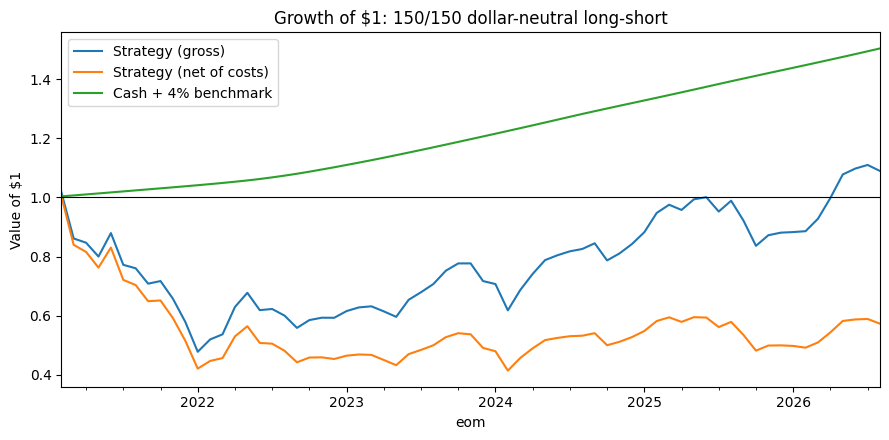

Strategy (gross)           1.089
Strategy (net of costs)    0.573
Cash + 4% benchmark        1.504
Name: 2026-08-31 00:00:00, dtype: float64


In [71]:
cum = (1 + df[['dn_total', 'dn_net', 'bench']]).cumprod()
cum.columns = ['Strategy (gross)', 'Strategy (net of costs)', 'Cash + 4% benchmark']

cum.plot(figsize=(9, 4.5), title='Growth of $1: 150/150 dollar-neutral long-short')
plt.axhline(1, color='black', linewidth=0.8)
plt.ylabel('Value of $1')
plt.tight_layout(); plt.show()

print(cum.iloc[-1].round(3))    # ending value of $1

In [72]:
oos.to_parquet('/content/drive/MyDrive/FIAM Hackathon/oos_ridge.parquet')
df[['dn_total', 'dn_net', 'rf', 'mkt', 'bench']].to_parquet('/content/drive/MyDrive/FIAM Hackathon/returns_ridge.parquet')